In [4]:
import sys
!{sys.executable} -m pip install numpy matplotlib opencv-python tensorflow keras

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.0.2-cp39-cp39-macosx_14_0_arm64.whl (5.3 MB)
     |████████████████████████████████| 7.8 MB 2.8 MB/s eta 0:00:01
     |████████████████████████████████| 48.3 MB 1.1 MB/s eta 0:00:011
     |████████████████████████████████| 200.4 MB 974 kB/s eta 0:00:01     |██████████████████████████▊     | 167.6 MB 983 kB/s eta 0:00:34
     |████████████████████████████████| 1.4 MB 11.0 MB/s eta 0:00:01
     |████████████████████████████████| 2.9 MB 12.7 MB/s eta 0:00:01
     |████████████████████████████████| 249 kB 14.1 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 8.6 MB/s  eta 0:00:01
     |████████████████████████████████| 122 kB 13.7 MB/s eta 0:00:01
     |████████████████████████████████| 4.7 MB 10.0 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 5.5 MB/s eta 0:00:01
     |████████████████████████████████| 71 kB 1.5 MB/s eta 0:00:011
     |███████████████████████

In [6]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
import cv2


In [7]:
from tensorflow.keras.utils import img_to_array

In [8]:
train_datagen = ImageDataGenerator(rescale = 1./255,
shear_range = 0.2,
zoom_range = 0.2,
horizontal_flip = True)

In [32]:
train_images = "/Users/pujithraavi/Desktop/ml nemo/chest_xray/train"
train_images = "/Users/pujithraavi/Desktop/ml nemo/chest_xray/train"
val_images = "/Users/pujithraavi/Desktop/ml nemo/chest_xray/val"
test_images = "/Users/pujithraavi/Desktop/ml nemo/chest_xray/test"

In [33]:
out_img="D:\\deep learning\\chestxray output.jpg"

In [34]:
train_generator = train_datagen.flow_from_directory(train_images,
    target_size = (300,300),
    batch_size = 128,
    class_mode = 'binary')

Found 5216 images belonging to 2 classes.


In [35]:
train_generator.class_indices

{'NORMAL': 0, 'PNEUMONIA': 1}

In [36]:
train_generator.classes.shape

(5216,)

In [37]:
test_datagen = ImageDataGenerator(rescale = 1./255)
validation_generator = test_datagen.flow_from_directory("/Users/pujithraavi/Desktop/ml nemo/chest_xray/train",
    target_size= (300,300),
    batch_size = 128,
    class_mode = 'binary')

Found 5216 images belonging to 2 classes.


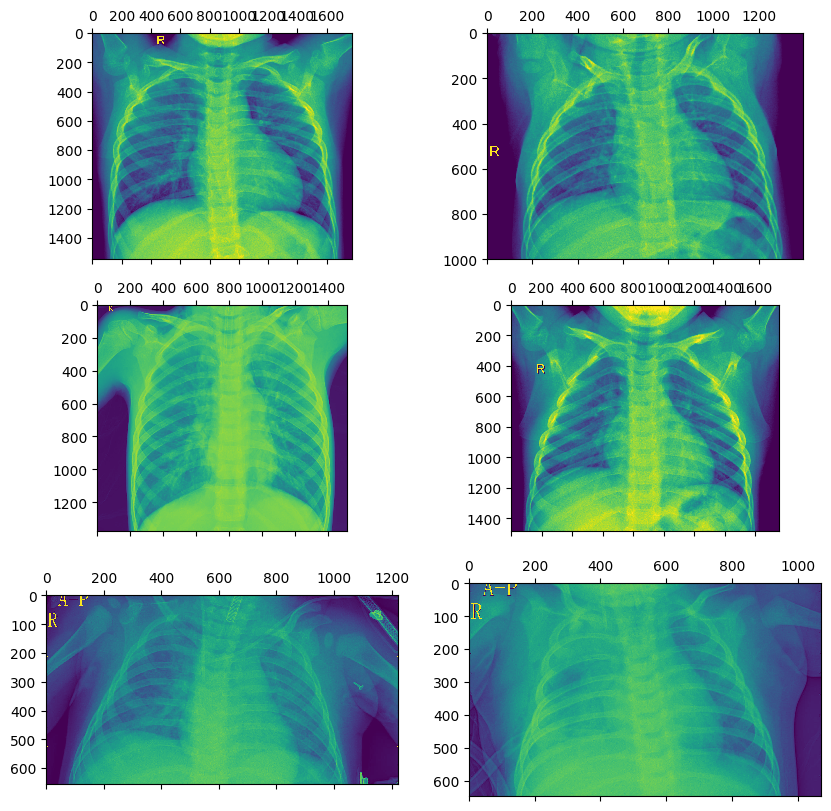

In [38]:
#Pneumonia
plot_image = plt.figure(figsize=(10,10))

plot1 = plot_image.add_subplot(3,2,1)
plot2 = plot_image.add_subplot(3,2,2)
plot3 = plot_image.add_subplot(3,2,3)
plot4 = plot_image.add_subplot(3,2,4)
plot5 = plot_image.add_subplot(3,2,5)
plot6 = plot_image.add_subplot(3,2,6)
plot1.matshow(plt.imread(train_generator.filepaths[41]))
plot2.matshow(plt.imread(train_generator.filepaths[176]))
plot3.matshow(plt.imread(train_generator.filepaths[1553]))
plot4.matshow(plt.imread(train_generator.filepaths[354]))
plot5.matshow(plt.imread(train_generator.filepaths[2679]))
plot6.matshow(plt.imread(train_generator.filepaths[2710]))

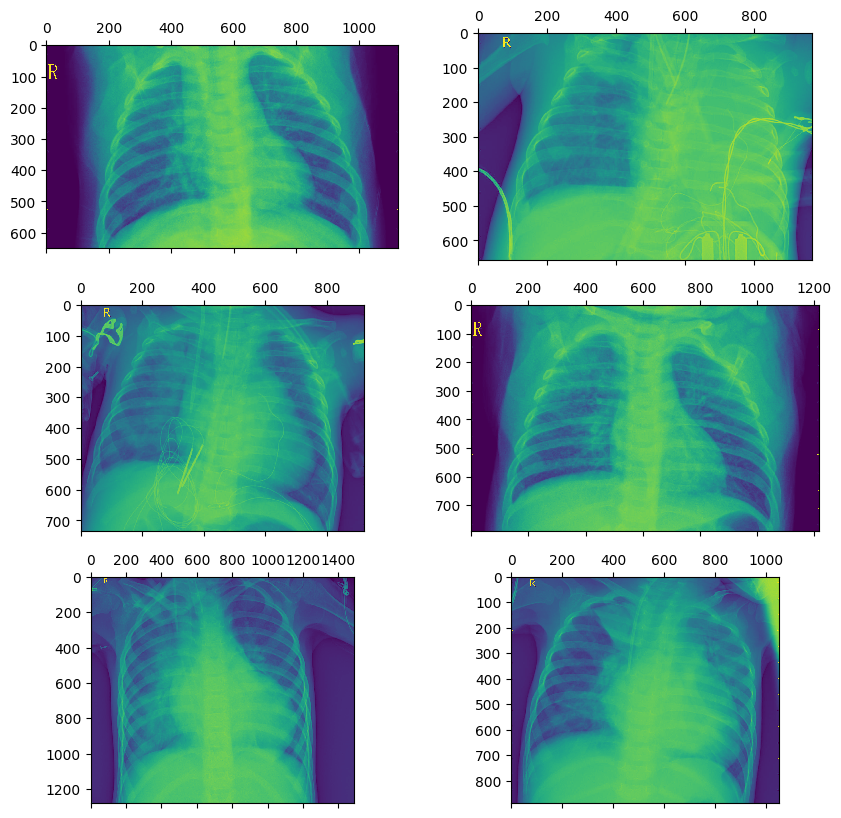

In [39]:
#Normal
plot_image = plt.figure(figsize=(10,10))

plot1 = plot_image.add_subplot(3,2,1)
plot2 = plot_image.add_subplot(3,2,2)
plot3 = plot_image.add_subplot(3,2,3)
plot4 = plot_image.add_subplot(3,2,4)
plot5 = plot_image.add_subplot(3,2,5)
plot6 = plot_image.add_subplot(3,2,6)
plot1.matshow(plt.imread(train_generator.filepaths[1419]))
plot2.matshow(plt.imread(train_generator.filepaths[1365]))
plot3.matshow(plt.imread(train_generator.filepaths[1400]))
plot4.matshow(plt.imread(train_generator.filepaths[1350]))
plot5.matshow(plt.imread(train_generator.filepaths[1345]))
plot6.matshow(plt.imread(train_generator.filepaths[1349]))

In [40]:
model= tf.keras.models.Sequential([
                                   tf.keras.layers.Conv2D(16, (3,3), activation= 'relu', input_shape= (300, 300, 3)),
                                   tf.keras.layers.MaxPool2D(2,2),
                                   tf.keras.layers.Conv2D(32, (3,3), activation= 'relu'),
                                   tf.keras.layers.MaxPool2D(2,2),
                                   tf.keras.layers.Conv2D(64, (3,3), activation= 'relu'),
                                   tf.keras.layers.MaxPool2D(2,2),
                                   tf.keras.layers.Conv2D(128, (3,3), activation= 'relu'),
                                   tf.keras.layers.MaxPool2D(2,2),
                                   tf.keras.layers.Conv2D(128, (3,3), activation= 'relu'),
                                   tf.keras.layers.MaxPool2D(2,2),

                                   tf.keras.layers.Flatten(),
                                   tf.keras.layers.Dense(256, activation= 'relu'),
                                   tf.keras.layers.Dense(512, activation= 'relu'),
                                   tf.keras.layers.Dense(1, activation= 'sigmoid')
])
model.summary()
model.compile(optimizer= 'adam', loss= 'binary_crossentropy', metrics= ['accuracy'])

/Users/pujithraavi/Library/Python/3.9/lib/python/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 298, 298, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 149, 149, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 147, 147, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 73, 73, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 71, 71, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 35, 35, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 33, 33, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     1,605,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,983,009 (7.56 MB)

 Trainable params: 1,983,009 (7.56 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
import sys
!{sys.executable} -m pip install scipy

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [42]:
history = model.fit(train_generator, epochs = 2, validation_data = validation_generator)

Epoch 1/2
41/41 ━━━━━━━━━━━━━━━━━━━━ 156s 4s/step - accuracy: 0.7002 - loss: 0.6481 - val_accuracy: 0.7535 - val_loss: 0.5327
Epoch 2/2
41/41 ━━━━━━━━━━━━━━━━━━━━ 170s 4s/step - accuracy: 0.7614 - loss: 0.4888 - val_accuracy: 0.7795 - val_loss: 0.4170


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 157ms/step
predicted class is : [[0.91575384]
 [0.54504186]
 [0.9072331 ]
 [0.87536335]
 [0.79444146]
 [0.83875346]
 [0.50293624]
 [0.78794545]
 [0.8544051 ]
 [0.85895896]
 [0.56696594]
 [0.9883127 ]
 [0.7605158 ]
 [0.6351122 ]
 [0.8114802 ]
 [0.97353417]
 [0.96787864]
 [0.95408833]
 [0.9364551 ]
 [0.37068126]
 [0.603443  ]
 [0.48413077]
 [0.38587186]
 [0.96456003]
 [0.98638844]
 [0.98987603]
 [0.94563854]
 [0.965045  ]
 [0.84166104]
 [0.9844064 ]
 [0.95669603]
 [0.44835246]
 [0.39855075]
 [0.97585344]
 [0.4977842 ]
 [0.93794096]
 [0.7587671 ]
 [0.92160064]
 [0.7627518 ]
 [0.9278176 ]
 [0.6209238 ]
 [0.9115463 ]
 [0.95874125]
 [0.9800293 ]
 [0.5659218 ]
 [0.91315526]
 [0.9294752 ]
 [0.64079136]
 [0.680031  ]
 [0.92567986]
 [0.8652771 ]
 [0.91529644]
 [0.9238738 ]
 [0.9411851 ]
 [0.9737831 ]
 [0.93314946]
 [0.99066716]
 [0.8143771 ]
 [0.9899375 ]
 [0.8619493 ]
 [0.93333024]
 [0.8913783 ]
 [0.92293024]
 [0.98975   ]
 [0.9591433 ]
 [0.9522615 ]
 [0.52923983]
 [

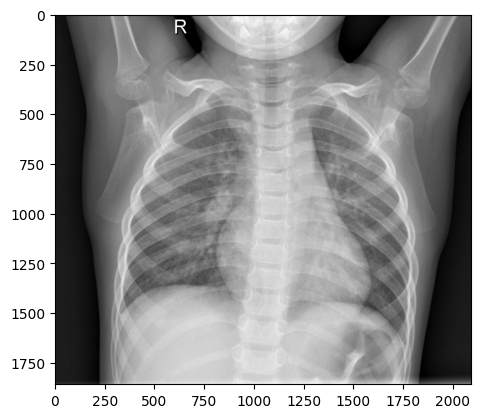

In [43]:
pre=model.predict(validation_generator.__getitem__(0)[0])
print('predicted class is : {}'.format(pre))
img = plt.imread(validation_generator.filepaths[0])
plt.imshow(img, cmap='gray')

In [44]:
test_generator = test_datagen.flow_from_directory(
    test_images,
    target_size=(300, 300),
    batch_size=128,
    class_mode='binary',
    shuffle=False
)

Found 624 images belonging to 2 classes.


In [45]:
x_train,y_train=next(train_generator)
x_test,y_test=next(test_generator)

In [46]:
loss = history.history['loss']
val_loss = history.history['val_loss']

In [47]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

In [50]:
import os

print(os.getcwd())

/Users/pujithraavi/Desktop/ml nemo


In [51]:
os.listdir()

['.DS_Store', 'chest_xray', 'main (1).ipynb', 'archive (1).zip']

In [54]:
eval_datagen = ImageDataGenerator(rescale = 1/255)

test_generator = eval_datagen.flow_from_directory(
    "/Users/pujithraavi/Desktop/ml nemo/chest_xray/test",
    target_size = (300, 300),
    batch_size = 128, 
    class_mode = 'binary'
)

eval_result = model.evaluate(test_generator)
print('loss :', eval_result[0])
print('accuracy :', eval_result[1])

Found 624 images belonging to 2 classes.
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 624ms/step - accuracy: 0.6594 - loss: 0.6620
loss : 0.7028912305831909
accuracy : 0.6410256624221802


In [60]:
import cv2
import numpy as np

image_path = "/Users/pujithraavi/Desktop/ml nemo/chest_xray/test/NORMAL/IM-0017-0001.jpeg"

img = cv2.imread(image_path)

if img is None:
    print("Image not found. Check the file path.")
else:
    img = cv2.resize(img, (300,300))
    img = img.astype("float32") / 255.0
    img = np.expand_dims(img, axis=0)

    prediction = model.predict(img)

    print(prediction)

    if prediction[0][0] > 0.5:
        print("PNEUMONIA")
    else:
        print("NORMAL")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
[[0.8104]]
PNEUMONIA


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Prediction: Pneumonia


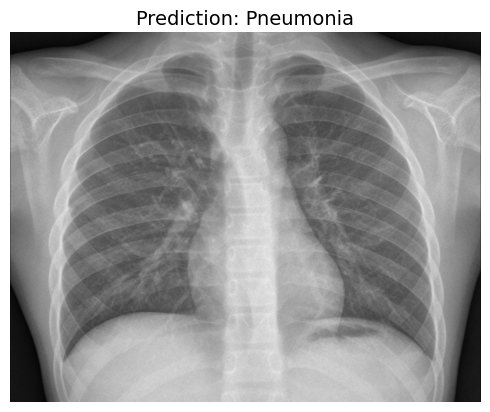

In [62]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = r"/Users/pujithraavi/Desktop/ml nemo/chest_xray/test/NORMAL/IM-0017-0001.jpeg"

# Read image
img = cv2.imread(image_path)

# Save a copy for display
tempimg = img.copy()

# Resize for model
img = cv2.resize(img, (300, 300))
img = img.astype("float32") / 255.0
img = np.expand_dims(img, axis=0)

# Predict
prediction = model.predict(img)

if prediction[0][0] >= 0.5:
    label = "Pneumonia"
else:
    label = "Normal"

print("Prediction:", label)

# Convert BGR to RGB for matplotlib
tempimg = cv2.cvtColor(tempimg, cv2.COLOR_BGR2RGB)

plt.imshow(tempimg)
plt.title(f"Prediction: {label}", fontsize=14)
plt.axis("off")
plt.show()

In [65]:
%pip install lime

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 275 kB 2.0 MB/s eta 0:00:01
     |████████████████████████████████| 78 kB 15.4 MB/s eta 0:00:01
  Using cached scikit_learn-1.6.1-cp39-cp39-macosx_12_0_arm64.whl (11.1 MB)
     |████████████████████████████████| 13.4 MB 17.6 MB/s eta 0:00:01
     |████████████████████████████████| 317 kB 19.7 MB/s eta 0:00:01
     |████████████████████████████████| 227 kB 31.1 MB/s eta 0:00:01
     |████████████████████████████████| 1.6 MB 33.1 MB/s eta 0:00:01
  Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283857 sha256=86dd47c79de0a180f9335a0fc626a42e35757839115a46ae5d29e4e69b270133
  Stored in directory: /Users/pujithraavi/Library/Caches/pip/wheels/ed/d7/c9/5a0130d06d6310bc6cbe55220e6e72dcb8c4eff9a478717066
Successfully built lime
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr

In [66]:
from lime import lime_image
import time

/Users/pujithraavi/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [67]:
explainer = lime_image.LimeImageExplainer()

In [68]:
explanation = explainer.explain_instance(validation_generator.__getitem__(0)[0][11].astype('double'), model.predict, top_labels=1, hide_color=0, num_samples=1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step


  1%|          | 10/1000 [00:00<00:28, 35.28it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


  2%|▏         | 20/1000 [00:00<00:17, 56.03it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


... (187 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


 99%|█████████▉| 989/1000 [00:11<00:00, 102.94it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


100%|██████████| 1000/1000 [00:11<00:00, 85.08it/s]


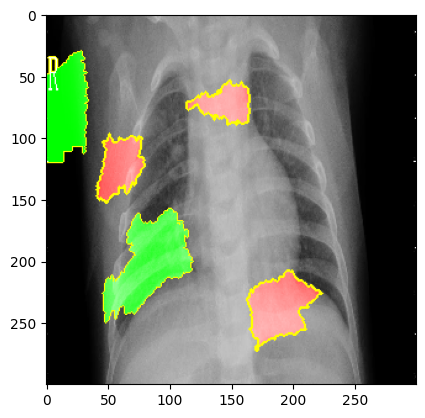

In [69]:
from skimage.segmentation import mark_boundaries
temp, mask = explanation.get_image_and_mask(explanation.top_labels[0], positive_only=False, num_features=5, hide_rest=False)
plt.imshow(mark_boundaries(temp, mask))

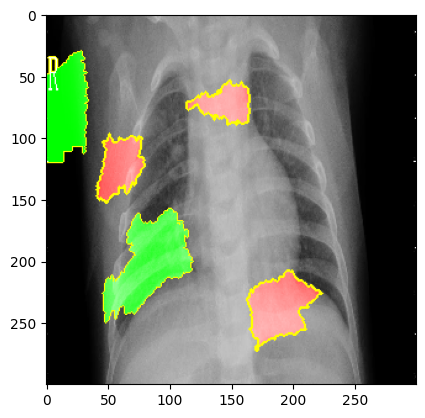

In [70]:
temp1, mask1= explanation.get_image_and_mask(explanation.top_labels[0], positive_only=False, num_features=5, hide_rest=False)
plt.imshow(mark_boundaries(temp1, mask1))

(np.float64(-0.5), np.float64(299.5), np.float64(299.5), np.float64(-0.5))

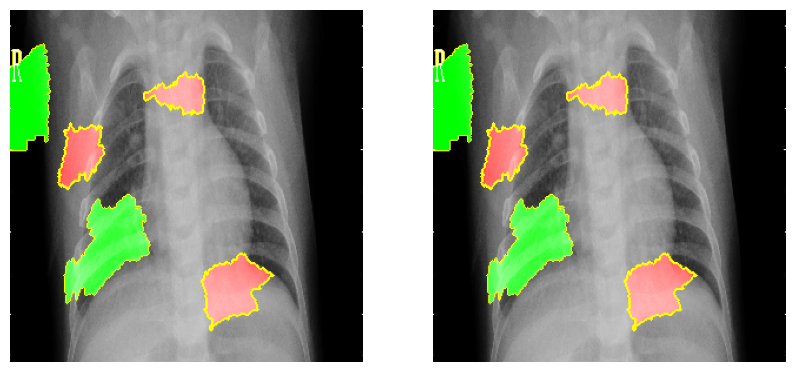

In [71]:
fig, (ax1,ax2)=plt.subplots(1,2,figsize=(10,10))
ax1.imshow(mark_boundaries(temp1, mask1))
ax2.imshow(mark_boundaries(temp, mask))
ax1.axis('off')
ax2.axis('off')

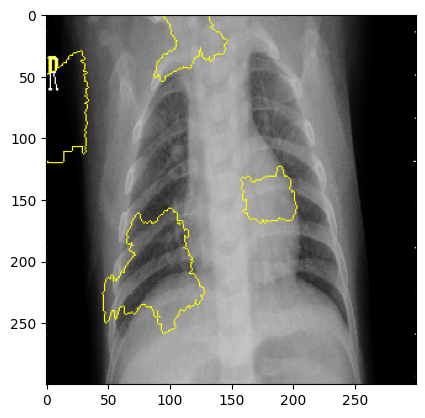

In [72]:
temp2, mask2= explanation.get_image_and_mask(explanation.top_labels[0], positive_only=True, num_features=5, hide_rest=False)
plt.imshow(mark_boundaries(temp2, mask2))

In [74]:
%pip install shap

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 556 kB 2.8 MB/s eta 0:00:01
     |████████████████████████████████| 10.8 MB 30.3 MB/s eta 0:00:01
     |████████████████████████████████| 2.7 MB 21.2 MB/s eta 0:00:01
     |████████████████████████████████| 28.8 MB 7.3 MB/s eta 0:00:011
     |████████████████████████████████| 349 kB 18.0 MB/s eta 0:00:01
     |████████████████████████████████| 510 kB 17.9 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [75]:
import shap
import numpy as np

# select a set of background examples to take an expectation over
background = x_train[np.random.choice(x_train.shape[0], 20, replace=False)]

# explain predictions of the model on three images
e = shap.DeepExplainer(model, background)
# ...or pass tensors directly
# e = shap.DeepExplainer((model.layers[0].input, model.layers[-1].output), background)
shap_values = e.shap_values(x_test[1:3])

/Users/pujithraavi/Library/Python/3.9/lib/python/site-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/Users/pujithraavi/Library/Python/3.9/lib/python/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_15
Received: inputs=['Tensor(shape=(20, 300, 300, 3))']
  warnings.warn(msg)
/Users/pujithraavi/Library/Python/3.9/lib/python/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_15
Received: inputs=['Tensor(shape=(40, 300, 300, 3))']
  warnings.warn(msg)
/Users/pujithraavi/Library/Python/3.9/lib/python/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't ma

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0023172448854893446..0.004812701605260372].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0007041486096568406..0.0018817454110831022].


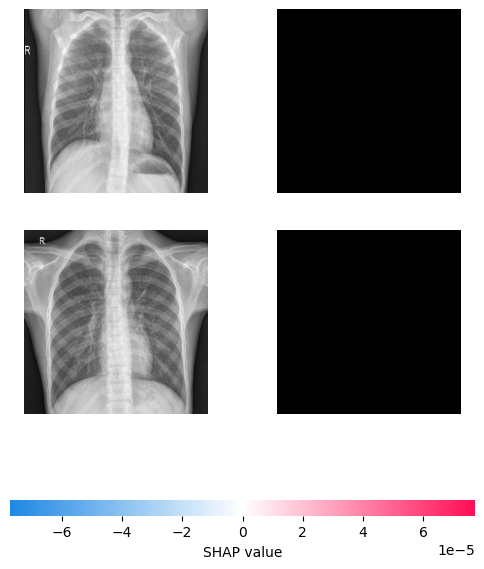

In [76]:
# plot the feature attributions
shap.image_plot(shap_values, x_test[1:3])

In [77]:
from lime import lime_image
from lime.wrappers.scikit_image import SegmentationAlgorithm
explainer = lime_image.LimeImageExplainer(verbose = False)
segmenter = SegmentationAlgorithm('quickshift', kernel_size=1, max_dist=200, ratio=0.2)

In [78]:
%%time
explanation = explainer.explain_instance(validation_generator.__getitem__(0)[0][1].astype('double'), 
                                         classifier_fn = model.predict, 
                                         top_labels=1, hide_color=0, num_samples=5000, segmentation_fn=segmenter)

  0%|          | 6/5000 [00:00<01:28, 56.64it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


  0%|          | 17/5000 [00:00<02:01, 40.93it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


  1%|          | 28/5000 [00:00<02:01, 40.97it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


... (992 outputs left out)

100%|█████████▉| 4998/5000 [02:14<00:00, 41.19it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


100%|██████████| 5000/5000 [02:14<00:00, 37.15it/s]


CPU times: user 3min 54s, sys: 4.27 s, total: 3min 58s
Wall time: 2min 15s


In [79]:
from skimage.color import gray2rgb, rgb2gray, label2rgb

Text(0.5, 1.0, 'Positive/Negative Regions for 0')

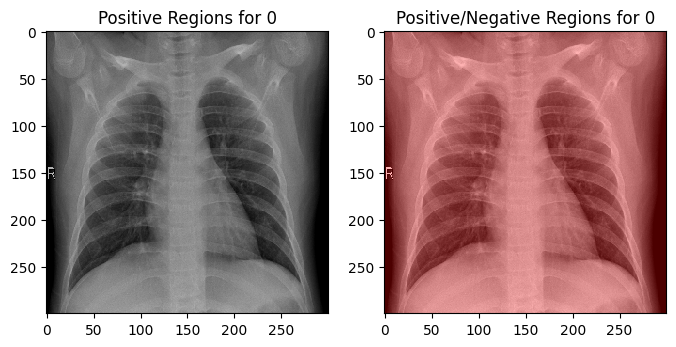

In [80]:
temp, mask = explanation.get_image_and_mask(explanation.top_labels[0], positive_only=True, num_features=10, hide_rest=False, min_weight = 0.01)
fig, (ax1, ax2) = plt.subplots(1,2, figsize = (8, 4))
ax1.imshow(label2rgb(mask,temp, bg_label = 0), interpolation = 'nearest')
ax1.set_title('Positive Regions for {}'.format(explanation.top_labels[0]))
temp, mask = explanation.get_image_and_mask(explanation.top_labels[0], positive_only=False, num_features=10, hide_rest=False, min_weight = 0.01)
ax2.imshow(label2rgb(3-mask,temp, bg_label = 0), interpolation = 'nearest')
ax2.set_title('Positive/Negative Regions for {}'.format(explanation.top_labels[0]))